In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter
from multifractal_networks.utils.motifs import MotifGenerator

# Load Network

In [4]:
filename = './test_networks/horses_combined.txt'
G = nx.read_edgelist(filename)

In [5]:
len(G)

236

In [6]:
2 * G.number_of_edges() / G.number_of_nodes()

5.423728813559322

In [7]:
for m_size in [2,3,5,6,7,10,11]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size))+2)

2  k_max:  9
3  k_max:  6
5  k_max:  5
6  k_max:  5
7  k_max:  4
10  k_max:  4
11  k_max:  4


# Init Fitter

In [8]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9,
        'triangle':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.115636
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.047557


In [9]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 640},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 1891},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 816},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 2554},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 755},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 7236},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 5386},
 {'name': 'four_loop

# Grid Search

In [11]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,9]},
                {'m': 3,  'k': [1,6]},
                {'m': 5,  'k': [1,5]},
                {'m': 6,  'k': [1,5]},
                {'m': 7,  'k': [1,4]},
                {'m': 10, 'k': [1,4]},
                {'m': 11, 'k': [1,4]}],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-01-29 07:58:13,940] A new study created in memory with name: no-name-7f8103ab-0888-435a-8a0c-e2f2d8564f78


Grid Search requires 8 trials...


[I 2025-01-29 07:58:31,561] Trial 0 finished with value: 7.582043844842111 and parameters: {'m': 2, 'k': 7}. Best is trial 0 with value: 7.582043844842111.
[I 2025-01-29 07:58:47,990] Trial 1 finished with value: 7.670463402347691 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 7.582043844842111.
[I 2025-01-29 07:59:05,811] Trial 2 finished with value: 8.213359629589617 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 7.582043844842111.
[I 2025-01-29 07:59:23,138] Trial 3 finished with value: 8.363345088338654 and parameters: {'m': 2, 'k': 8}. Best is trial 0 with value: 7.582043844842111.
[I 2025-01-29 07:59:39,881] Trial 4 finished with value: 7.288437858185976 and parameters: {'m': 2, 'k': 4}. Best is trial 4 with value: 7.288437858185976.
[I 2025-01-29 07:59:53,671] Trial 5 finished with value: 8.235357869383742 and parameters: {'m': 2, 'k': 1}. Best is trial 4 with value: 7.288437858185976.
[I 2025-01-29 08:00:10,411] Trial 6 finished with value: 6.64513

Grid Search requires 5 trials...


[I 2025-01-29 08:01:00,779] Trial 0 finished with value: 7.568063521616701 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 7.568063521616701.
[I 2025-01-29 08:01:30,961] Trial 1 finished with value: 7.792900898295087 and parameters: {'m': 3, 'k': 1}. Best is trial 0 with value: 7.568063521616701.
[I 2025-01-29 08:02:00,755] Trial 2 finished with value: 7.07745170164089 and parameters: {'m': 3, 'k': 2}. Best is trial 2 with value: 7.07745170164089.
[I 2025-01-29 08:02:31,411] Trial 3 finished with value: 7.004491057009815 and parameters: {'m': 3, 'k': 4}. Best is trial 3 with value: 7.004491057009815.
[I 2025-01-29 08:03:10,542] Trial 4 finished with value: 7.09895033615544 and parameters: {'m': 3, 'k': 5}. Best is trial 3 with value: 7.004491057009815.
[I 2025-01-29 08:03:10,543] A new study created in memory with name: no-name-fc0837ce-1021-406e-a306-11c14a3d9250


Grid Search requires 4 trials...


... (6 outputs left out)

[I 2025-01-29 08:48:12,457] Trial 0 finished with value: 6.9313883211731016 and parameters: {'m': 10, 'k': 3}. Best is trial 0 with value: 6.9313883211731016.
[I 2025-01-29 08:54:19,347] Trial 1 finished with value: 6.7296086952839085 and parameters: {'m': 10, 'k': 2}. Best is trial 1 with value: 6.7296086952839085.
[I 2025-01-29 08:58:56,924] Trial 2 finished with value: 6.559979823814404 and parameters: {'m': 10, 'k': 1}. Best is trial 2 with value: 6.559979823814404.
[I 2025-01-29 08:58:56,926] A new study created in memory with name: no-name-f981a0a1-29dd-465c-8eef-e84b1579dc70


Grid Search requires 3 trials...


[I 2025-01-29 09:37:31,473] Trial 0 finished with value: 6.797658242714385 and parameters: {'m': 11, 'k': 3}. Best is trial 0 with value: 6.797658242714385.
[I 2025-01-29 09:45:04,256] Trial 1 finished with value: 6.036144196764933 and parameters: {'m': 11, 'k': 2}. Best is trial 1 with value: 6.036144196764933.
[I 2025-01-29 09:51:48,832] Trial 2 finished with value: 6.164332938106001 and parameters: {'m': 11, 'k': 1}. Best is trial 1 with value: 6.036144196764933.


Best parameters:  {'m': 11, 'k': 2}
Best energy:  8.08609666125954
Best KL-divergence:  0.06488791443743429
Best KLD augumented energy: 6.036144196764933
Best P matrix:
 [[3.04535235e-01 4.76351965e-13 4.05381009e-13 7.08798807e-14
  7.53568399e-03 4.56900818e-04 0.00000000e+00 7.75980489e-11
  0.00000000e+00 4.55036572e-01 3.43386340e-03]
 [4.76351965e-13 6.33535393e-01 5.65682260e-13 9.40892785e-13
  3.59476253e-11 1.00000000e+00 0.00000000e+00 1.87997843e-02
  1.01373220e-02 2.24854630e-03 2.02123675e-02]
 [4.05381009e-13 5.65682260e-13 9.45749617e-01 1.43445049e-13
  9.83413801e-03 1.94615079e-11 0.00000000e+00 1.33340454e-11
  0.00000000e+00 0.00000000e+00 9.79793423e-04]
 [7.08798807e-14 9.40892785e-13 1.43445049e-13 1.00000000e+00
  1.02321363e-12 0.00000000e+00 0.00000000e+00 1.00000000e+00
  1.42983957e-10 1.75093271e-04 4.92762595e-02]
 [7.53568399e-03 3.59476253e-11 9.83413801e-03 1.02321363e-12
  7.46583803e-01 9.69442501e-01 1.04890230e-11 6.65564651e-02
  8.38134032e-01 1

The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


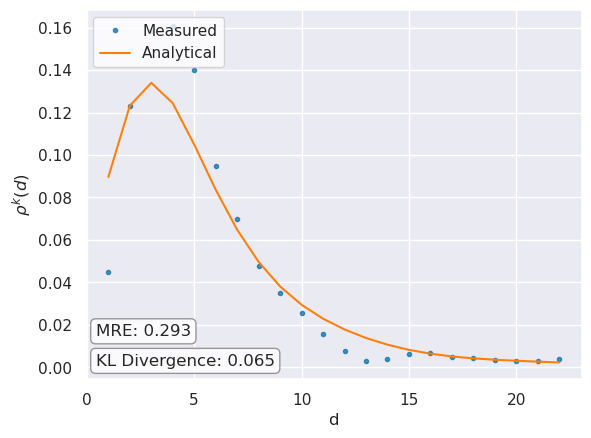

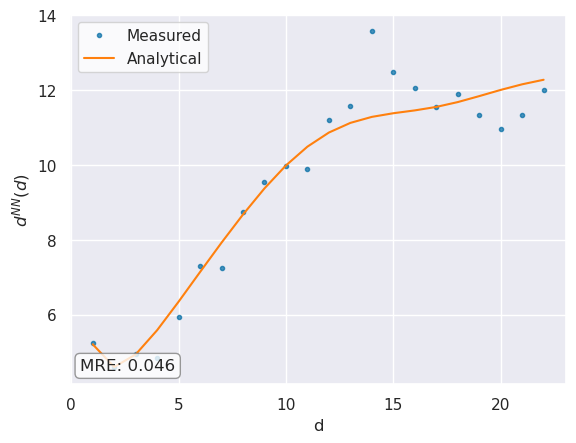

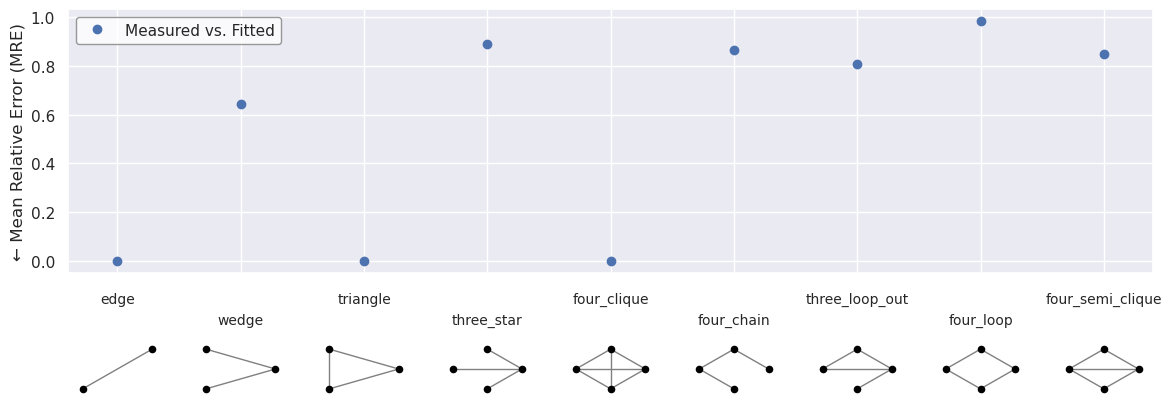

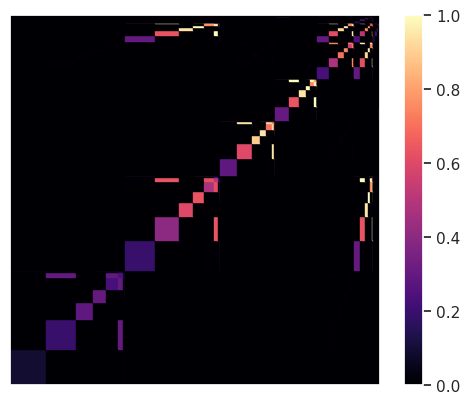

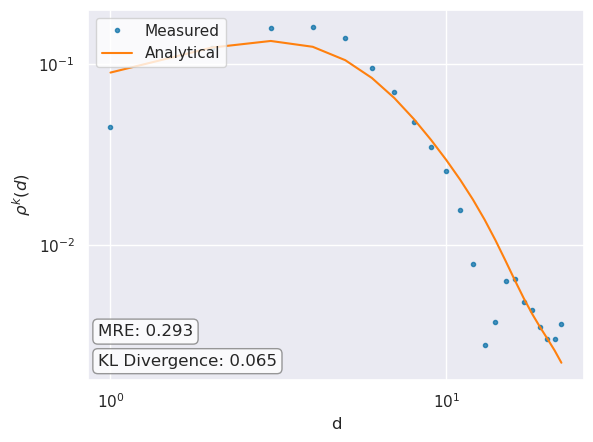

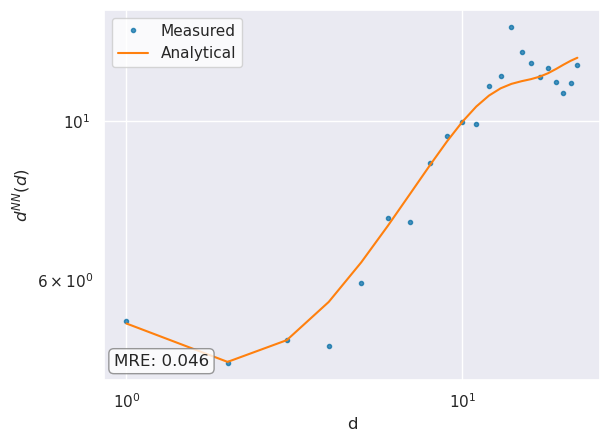

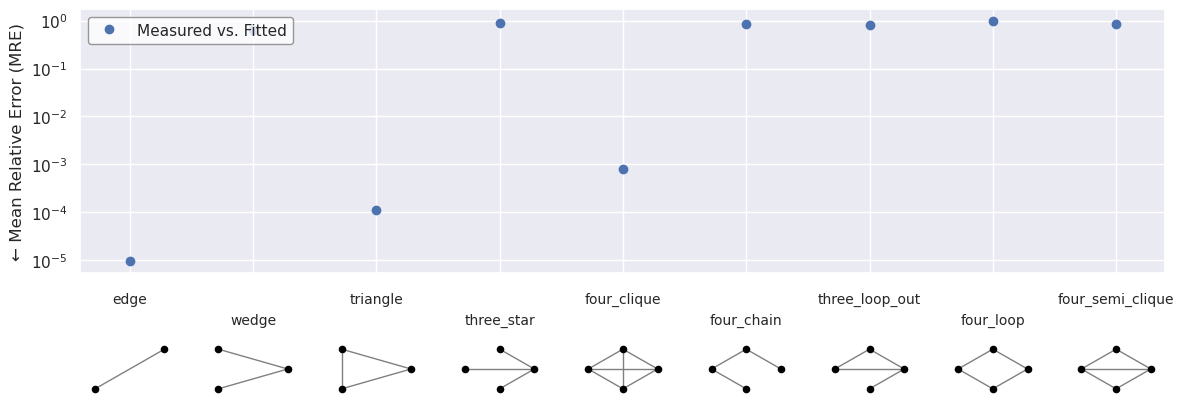

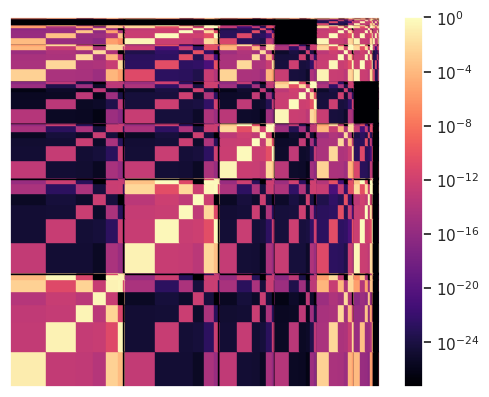

In [12]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_combined_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_combined_log_plot.pdf"
)

# Bootstrapping Stability

In [10]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'median'
)

Energy: 8.381572852477053
KL-divergence: 0.09457671976769348
KLD augumented energy: 7.0678816376514755
Gathering statistics (30 runs)...


100%|██████████| 30/30 [3:57:51<00:00, 475.71s/it]  

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:00.309221
Energy = 8.16 (7.72, 8.40)
l = [0.32 (0.18, 0.49), 0.19 (0.16, 0.28), 0.17 (0.14, 0.19), 0.15 (0.09, 0.18), 0.09 (0.02, 0.16), 0.03 (0.00, 0.14), 0.01 (0.00, 0.05), 0.00 (0.00, 0.04), 0.00 (0.00, 0.01), 0.00 (0.00, 0.00), 0.00 (0.00, 0.00)]
P = [
[0.24 (0.05, 0.65), 0.00 (0.00, 0.01), 0.00 (0.00, 0.81), 0.00 (0.00, 0.06), 0.00 (0.00, 0.50), 0.00 (0.00, 0.66), 0.02 (0.00, 0.90), 0.03 (0.00, 1.00), 0.11 (0.00, 0.95), 0.08 (0.00, 0.92), 0.11 (0.00, 0.60)],

[0.00 (0.00, 0.01), 0.60 (0.06, 0.96), 0.00 (0.00, 0.86), 0.00 (0.00, 0.94), 0.00 (0.00, 0.87), 0.00 (0.00, 1.00), 0.02 (0.00, 0.93), 0.03 (0.00, 1.00), 0.08 (0.00, 0.98), 0.25 (0.00, 0.99), 0.14 (0.00, 0.98)],

[0.00 (0.00, 0.81), 0.00 (0.00, 0.86), 0.86 (0.01, 1.00), 0.00 (0.00, 0.97), 0.00 (0.00, 0.94), 0.00 (0.00, 0.99), 0.04 (0.00, 1.00), 0.06 (0.00, 1.00), 0.29 (0.00, 1.00), 0.25 (0.00, 1.00), 0.12 (0.00, 1.00)],

[0.00 (0.00, 0.06), 0.00 (0.00, 0.94), 0.00 (0.00, 0.97), 0.89 (0.00, 1.00),

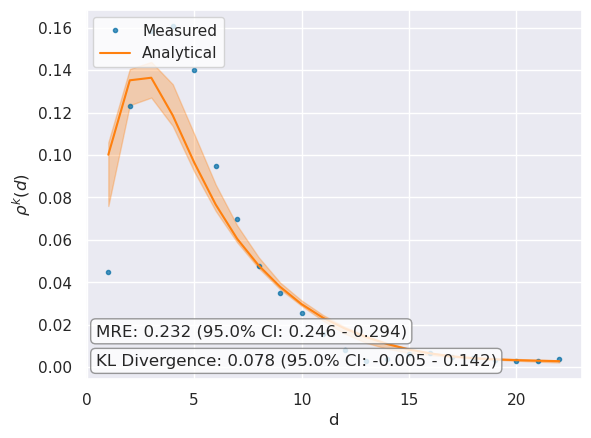

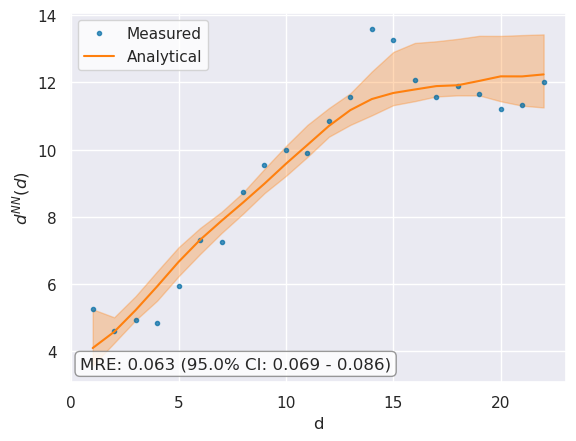

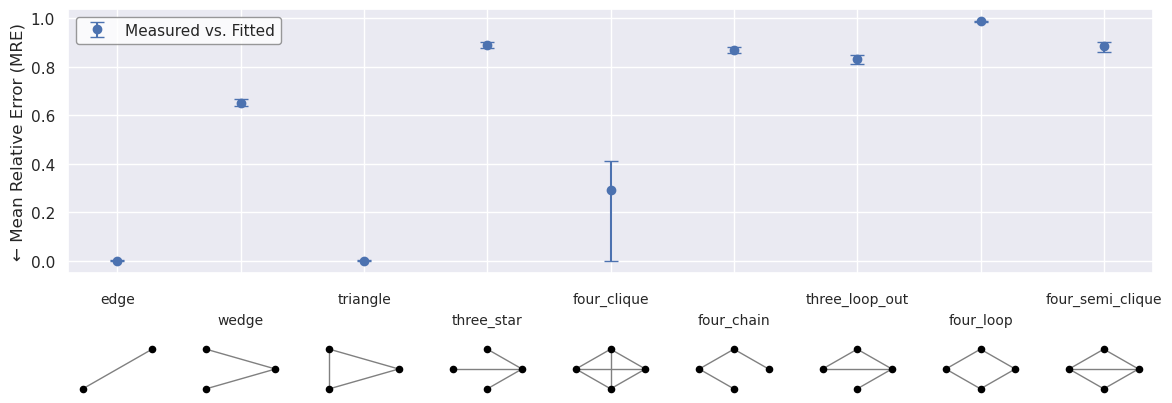

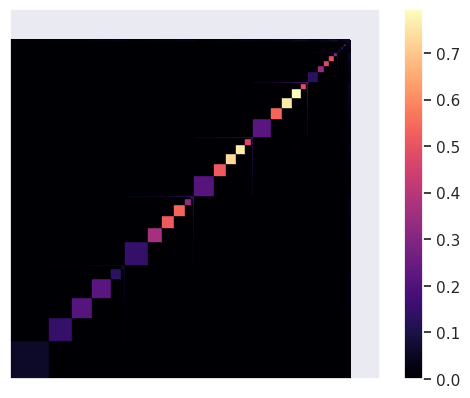

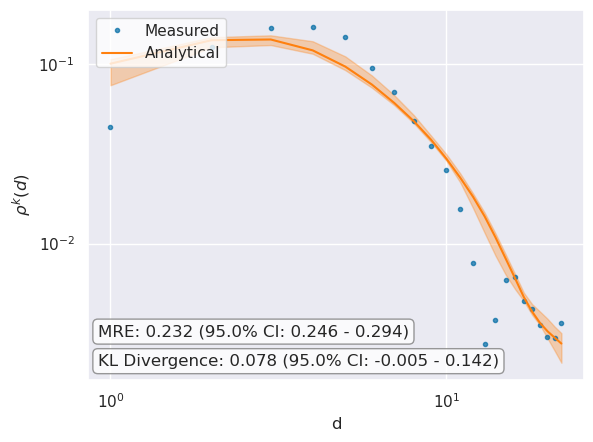

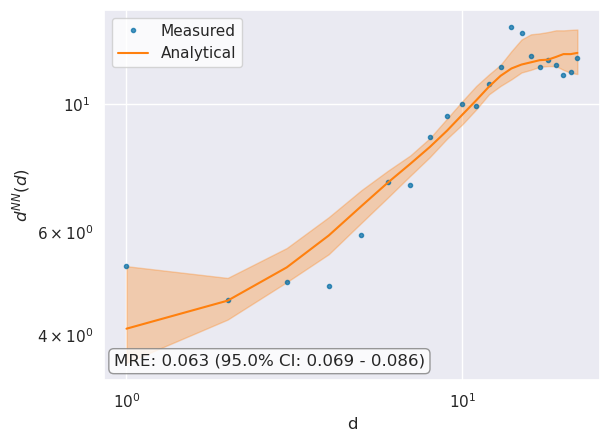

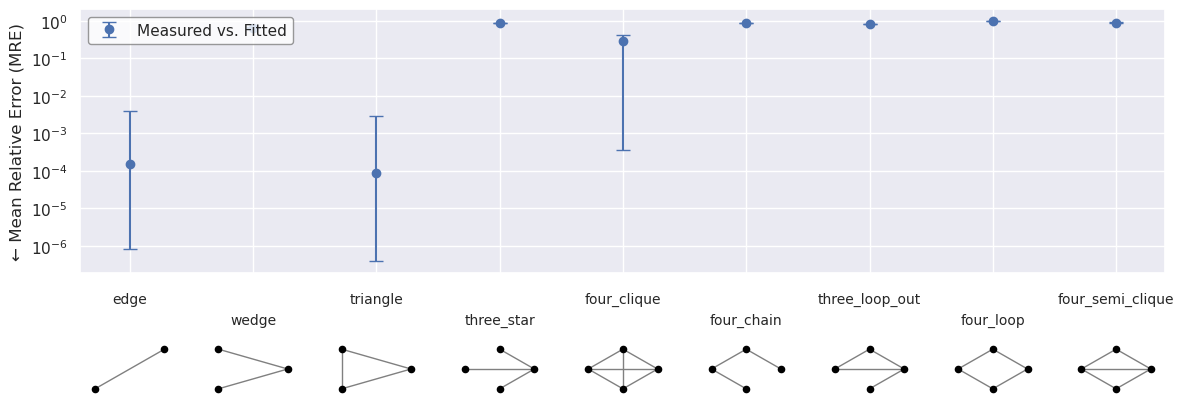

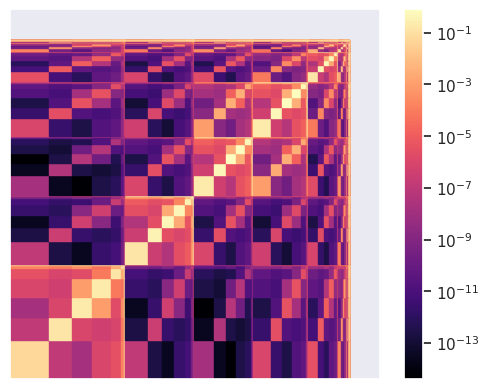

In [11]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_combined_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_combined_log_plot.pdf"
)

In [12]:
mfnf.P

array([[2.44608239e-01, 4.74807795e-07, 6.05621785e-08, 4.31981847e-06,
        1.36092820e-05, 6.25574639e-04, 2.30644426e-02, 2.85737563e-02,
        1.06760187e-01, 7.96192633e-02, 1.06377391e-01],
       [4.74807795e-07, 6.03584710e-01, 4.31981626e-06, 1.78332633e-06,
        3.79777995e-06, 3.29560367e-04, 2.10627691e-02, 2.53670871e-02,
        8.01990006e-02, 2.51293689e-01, 1.37174014e-01],
       [6.05621785e-08, 4.31981626e-06, 8.55989403e-01, 3.61323809e-03,
        7.60730910e-06, 1.39719118e-03, 4.16643252e-02, 6.27754984e-02,
        2.85096103e-01, 2.51690238e-01, 1.17189838e-01],
       [4.31981847e-06, 1.78332633e-06, 3.61323809e-03, 8.91062101e-01,
        3.12907467e-04, 2.02908876e-04, 5.94188299e-03, 1.02271786e-01,
        2.81562849e-01, 3.06456433e-01, 2.17659971e-01],
       [1.36092820e-05, 3.79777995e-06, 7.60730910e-06, 3.12907467e-04,
        5.50884898e-01, 1.10667915e-02, 4.00170075e-02, 2.12006694e-01,
        2.69225377e-01, 2.25905973e-01, 2.66052168e-

In [13]:
mfnf.l

array([3.23821411e-01, 1.94592395e-01, 1.66828403e-01, 1.54848314e-01,
       8.52487110e-02, 2.54704308e-02, 5.39491032e-03, 2.02710846e-03,
       4.40106246e-05, 4.89979717e-08, 2.64582281e-09])

# Generate Variants

Initializing...
0.0005593299865722656
Calculating betweenness...
Done.
Calculating node positions...
Done.


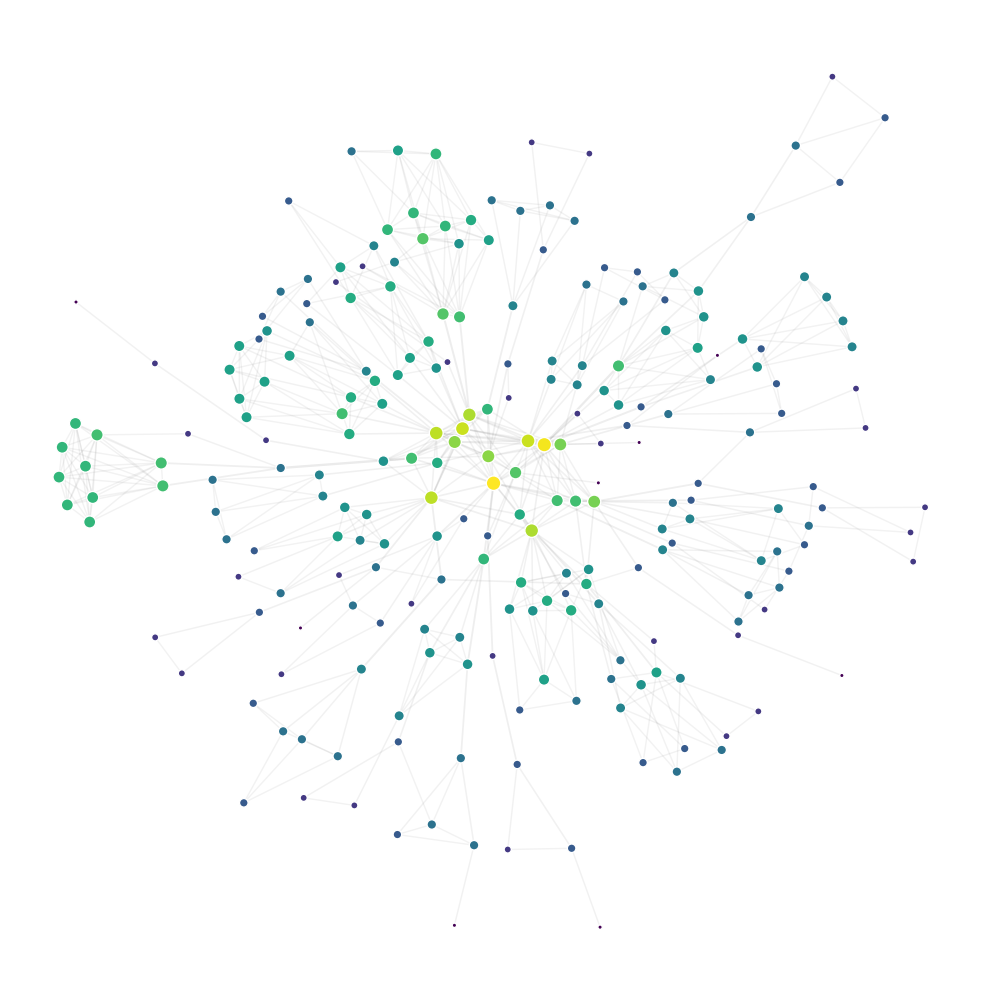

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 930.67it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


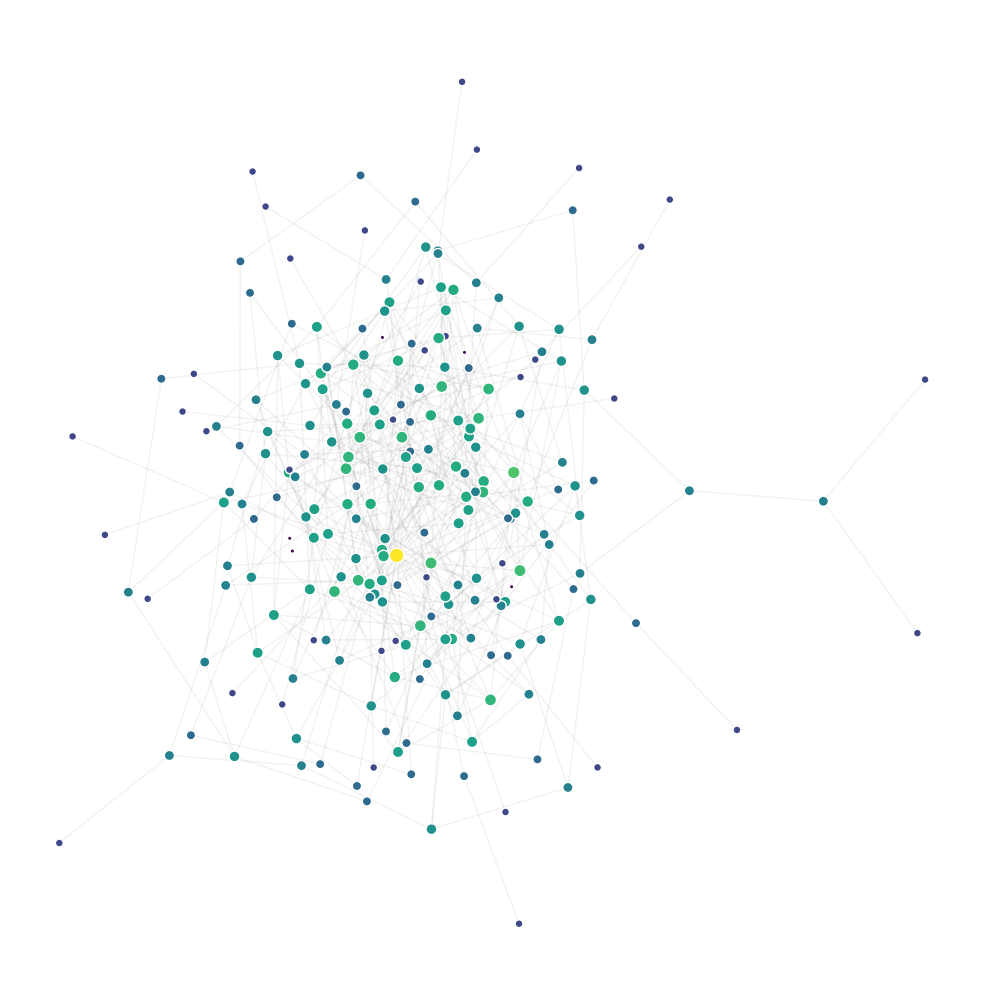

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 802.15it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


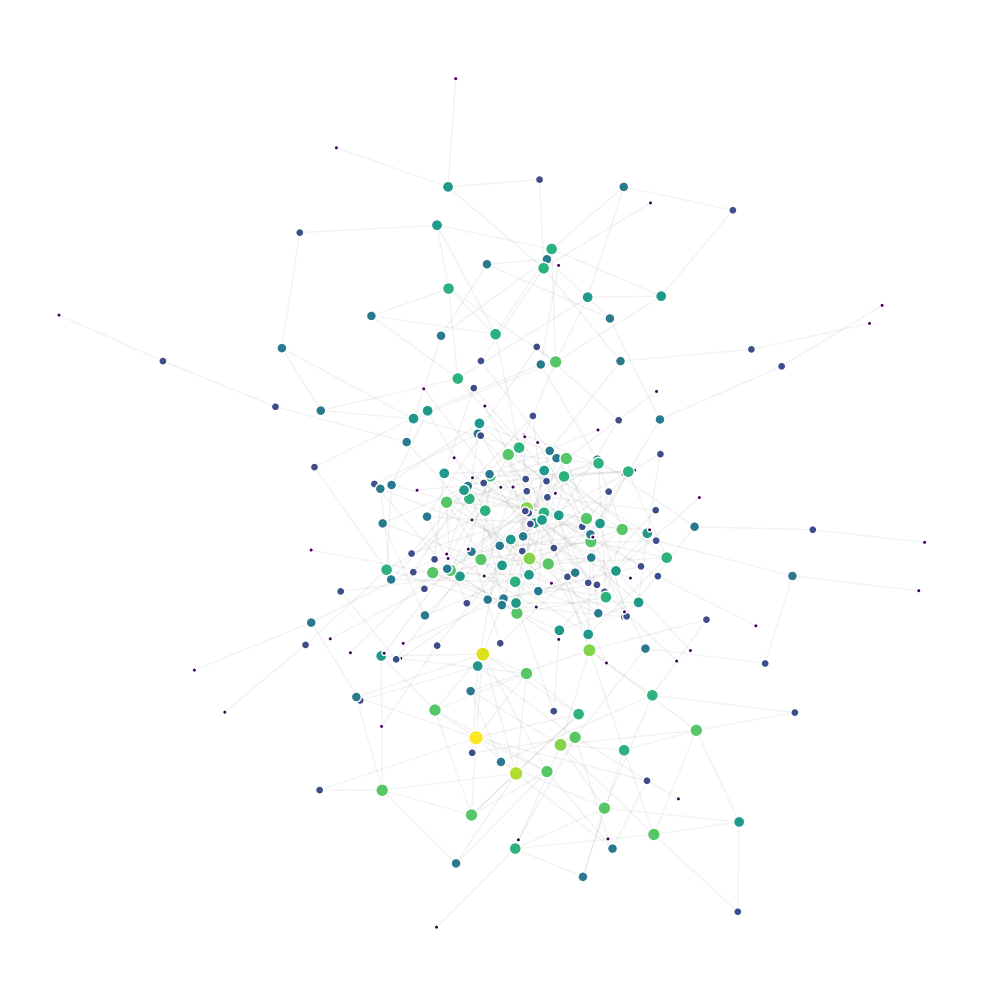

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 859.75it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


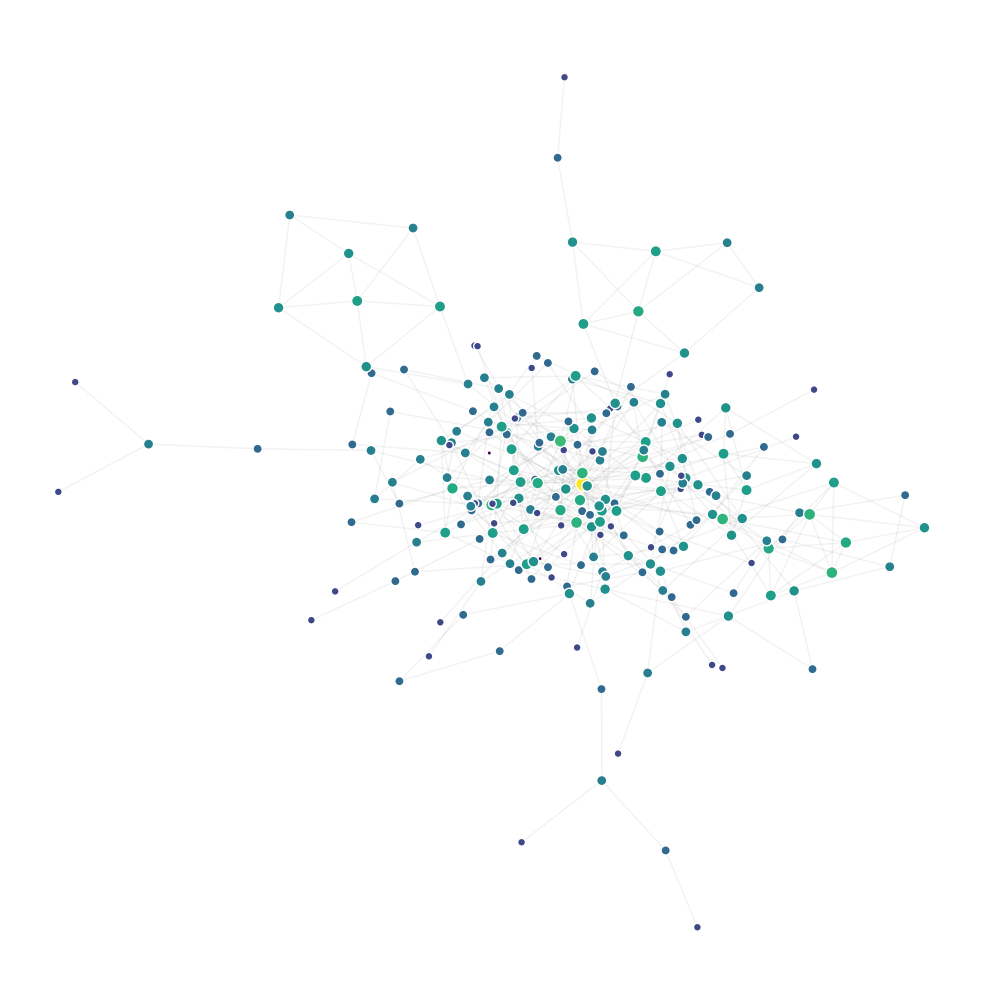

In [14]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.kamada_kawai_layout,
        'figsize': (10,10),
        'filename':  "figures/horses_combined_variants.pdf"
    },
    filename = "variant_networks/horses_combined_variants.graphml"
)